### Kaggle Dataset Downloader
Run the cell below to download any Kaggle dataset. You will need your Kaggle username and API key (which can be generated in your Kaggle Account settings as `kaggle.json`).

In [1]:
import os
import zipfile

# Ensure kaggle CLI is installed
!pip install -q kaggle

# --- Instructions ---
# Please upload your 'kaggle.json' file to /content/ (or your current directory)
# or copy it to '~/.kaggle/kaggle.json' before running this cell.

# Set up directory for Kaggle credentials
kaggle_dir = os.path.expanduser('~/.kaggle')
os.makedirs(kaggle_dir, exist_ok=True)

# If kaggle.json is uploaded in current workspace, move it to the correct folder
if os.path.exists('kaggle.json'):
    os.rename('kaggle.json', os.path.join(kaggle_dir, 'kaggle.json'))
    os.chmod(os.path.join(kaggle_dir, 'kaggle.json'), 0o600)

# Configuration
KAGGLE_DATASET = 'yasserh/uber-fares-dataset'
TARGET_NAME = 'uber.csv'

# Download dataset zip using official Kaggle API
!kaggle datasets download -d {KAGGLE_DATASET}

# Extract zip and rename/move the csv file
zip_filename = KAGGLE_DATASET.split('/')[-1] + '.zip'
if os.path.exists(zip_filename):
    with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
        zip_ref.extractall('temp_extracted')

    # Find the csv and place it at root
    for root, dirs, files in os.walk('temp_extracted'):
        for file in files:
            if file.endswith('.csv'):
                os.rename(os.path.join(root, file), TARGET_NAME)
                print(f'Successfully saved dataset as {TARGET_NAME}')
                break

    # Clean up temporary files
    os.remove(zip_filename)
    import shutil
    shutil.rmtree('temp_extracted')
else:
    print("Ensure you have uploaded kaggle.json so the API can download the dataset.")

Dataset URL: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset
License(s): CC0-1.0
100% 7.04M/7.04M [00:00<00:00, 84.6MB/s]

Successfully saved dataset as uber.csv


Dataset shape after cleaning: (182148, 10)

--- Model Evaluation ---
Linear Regression -> R2: 0.0219, RMSE: 4.0841
Random Forest -> R2: 0.7524, RMSE: 2.0550


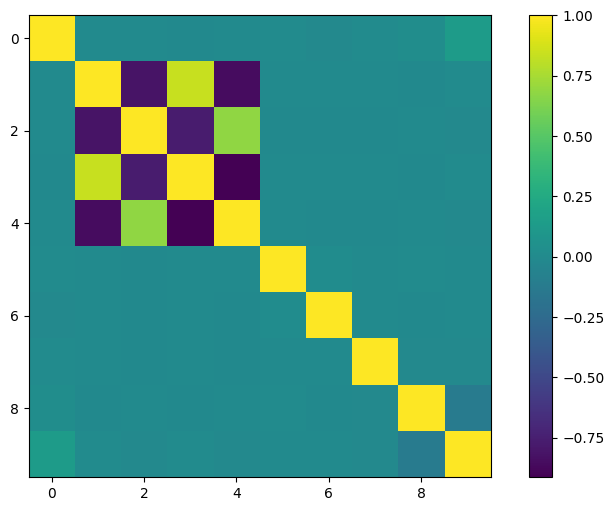

In [4]:
# Uber Fare Prediction - Simple Colab Script
# Dataset: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# 1. Load the dataset (upload uber.csv to Colab first)
df = pd.read_csv('uber.csv')

# 2. Pre-processing
# Convert datetime and extract useful time features
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year

# Drop columns not needed for the model
df = df.drop(['Unnamed: 0', 'key', 'pickup_datetime'], axis=1)

# Handle missing values (drop rows with NaN)
df = df.dropna()

# 3. Identify Outliers (using IQR on fare_amount)
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Remove fare outliers and negative fares
df = df[(df['fare_amount'] >= lower_bound) & (df['fare_amount'] <= upper_bound)]
df = df[df['fare_amount'] > 0]

# Also remove passenger_count outliers (0 passengers)
df = df[df['passenger_count'] > 0]

print("Dataset shape after cleaning:", df.shape)

# 4. Check Correlation
plt.figure(figsize=(10, 6))
corr = df.corr()
plt.imshow(corr)
plt.colorbar()

# 5. Prepare Features and Target
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

# Split data (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. Implement Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# 7. Implement Random Forest Regression (small n_estimators for speed in Colab)
rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# 8. Evaluate and Compare Models
def evaluate(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{name} -> R2: {r2:.4f}, RMSE: {rmse:.4f}")

print("\n--- Model Evaluation ---")
evaluate("Linear Regression", y_test, y_pred_lr)
evaluate("Random Forest", y_test, y_pred_rf)